In [75]:
capital = 100000
w_equity = 0.60
w_bonds = 0.30
w_gold = 0.10
print("check sum:",round(w_equity + w_bonds + w_gold),)
ret_equity= 0.124
vol_equity= 0.18
ret_bonds= 0.075
vol_bonds= 0.05
ret_gold= 0.115
vol_gold= 0.14

check sum: 1


In [63]:
import numpy as np

sim_ret_eq = np.random.normal(ret_equity, vol_equity)
print("Simulated Equity Return:", round(sim_ret_eq * 100, 2), "%")

sim_ret_bonds = np.random.normal(ret_bonds, vol_bonds)
sim_ret_gold = np.random.normal(ret_gold, vol_gold)

port_ret = (w_equity * sim_ret_eq) + (w_bonds * sim_ret_bonds) + (w_gold * sim_ret_gold)
ending_capital = capital * (1 + port_ret)

print("Portfolio Return:", round(port_ret * 100, 2), "%")
print("Ending Capital after 1 simulated year:", round(ending_capital, 2))

n_sims = 10000

sims_equity = np.random.normal(ret_equity, vol_equity, size=n_sims)
sims_bonds = np.random.normal(ret_bonds, vol_bonds, size=n_sims)
sims_gold = np.random.normal(ret_gold,vol_gold, size=n_sims)

sims_port_ret = (w_equity * sims_equity) + (w_bonds * sims_bonds) + (w_gold * sims_gold)
sims_ending_capital = capital * (1 + sims_port_ret)

print("number of simulated outcomes:", len(sims_ending_capital))
print("average ending capital:", round(np.mean(sims_ending_capital),2))

p5_capital= np.percentile(sims_ending_capital, 5)
var_1yr = capital - p5_capital

print("5th percentile  ending capital:", round(p5_capital, 2))
print( "1-year 95% VaR (Loss vs capital):", round(var_1yr,2))



Simulated Equity Return: 11.53 %
Portfolio Return: 12.16 %
Ending Capital after 1 simulated year: 112159.22
number of simulated outcomes: 10000
average ending capital: 110630.19
5th percentile  ending capital: 92526.98
1-year 95% VaR (Loss vs capital): 7473.02


In [64]:
stress_ret_equity = 0.04
stress_vol_equity = 0.30

stress_sims_equity = np.random.normal(stress_ret_equity, stress_vol_equity, size=n_sims)
stress_sims_bonds = np.random.normal(ret_bonds, vol_bonds, size=n_sims)
stress_sims_gold = np.random.normal(ret_gold, vol_gold, size=n_sims)

stress_port_ret = (w_equity * stress_sims_equity) + (w_bonds * stress_sims_bonds) + (w_gold * stress_sims_gold)
stress_ending_capital = capital * (1 + stress_port_ret)

stress_p5 = np.percentile(stress_ending_capital, 5)
stress_var = capital - stress_p5

print("Stress Average Ending Capital:", round(np.mean(stress_ending_capital), 2))
print("Stress 5th Percentile Capital:", round(stress_p5, 2))
print("Stress 1-Year 95% VaR:", round(stress_var, 2))

Stress Average Ending Capital: 105927.06
Stress 5th Percentile Capital: 76301.62
Stress 1-Year 95% VaR: 23698.38


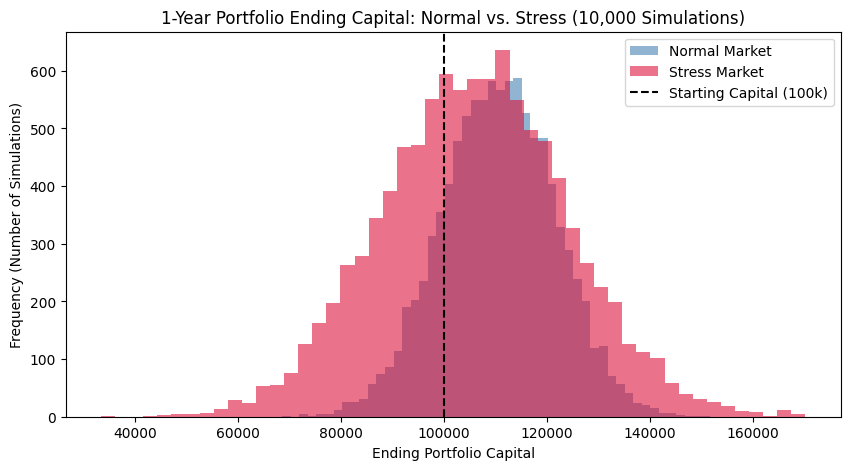

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(sims_ending_capital, bins=50, alpha=0.6, label="Normal Market", color="steelblue")
plt.hist(stress_ending_capital, bins=50, alpha=0.6, label="Stress Market", color="crimson")

plt.axvline(capital, color="black", linestyle="--", label="Starting Capital (100k)")
plt.title("1-Year Portfolio Ending Capital: Normal vs. Stress (10,000 Simulations)")
plt.xlabel("Ending Portfolio Capital")
plt.ylabel("Frequency (Number of Simulations)")
plt.legend()
plt.show()

In [66]:
import pandas as pd

summary_table = pd.DataFrame({
    "Scenario": ["Normal Market", "Equity Stress Market"],
    "Average Ending Capital": [
        round(np.mean(sims_ending_capital), 2),
        round(np.mean(stress_ending_capital), 2)
    ],
    "5th Percentile Capital": [
        round(p5_capital, 2),
        round(stress_p5, 2)
    ],
    "1-Year 95% VaR": [
        round(var_1yr, 2),
        round(stress_var, 2)
    ]
})

print(summary_table.to_string(index=False))

            Scenario  Average Ending Capital  5th Percentile Capital  1-Year 95% VaR
       Normal Market               110630.19                92526.98         7473.02
Equity Stress Market               105927.06                76301.62        23698.38
